# JII Time Series Forecasting: Return & Volatility

## Tujuan
- Menguji apakah return harian saham JII bisa diprediksi (ARIMA vs baseline naive)
- Memodelkan dan memprediksi volatilitas memakai GARCH
- Membandingkan model statistik (GARCH) dengan model Machine Learning (Random Forest) memakai walk-forward validation

## Data
- Universe: 30 konstituen Jakarta Islamic Index (JII), periode efektif 2 Jun – 30 Nov 2026
- Benchmark: Indeks JII (^JKII)
- Periode: 2 tahun (Sep 2024 – Sep 2026), data harian dari Yahoo Finance

## Struktur Notebook
1. Setup & Data Collection
2. Data Cleaning
3. Stylized Facts & Uji Stasioneritas
4. ARIMA: Apakah Return Bisa Diprediksi?
5. GARCH: Model & Forecast Volatilitas
6. Machine Learning untuk Volatilitas (Walk-Forward)
7. Evaluasi Forecast: GARCH vs ML vs Baseline
8. Aplikasi: VaR Dinamis Berbasis GARCH
9. Insight & Kesimpulan

## 1. Setup & Data Collection

Section ini menyiapkan library dan mengambil data harga harian 30 saham konstituen JII beserta indeks JII sebagai benchmark.

Library utama:
- `statsmodels` untuk ARIMA, uji ADF, ACF/PACF, dan uji ARCH
- `arch` untuk model GARCH
- `scikit-learn` untuk model Random Forest dan metrik evaluasi

Harga memakai `auto_adjust=True` supaya sudah disesuaikan dengan dividen dan stock split. Di akhir section ditampilkan ringkasan missing data per saham sebagai dasar keputusan cleaning di Section 2.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from arch import arch_model
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid')

# Konstituen JII periode 2 Jun - 30 Nov 2026
jii_tickers = [
    'AADI', 'ADMR', 'ADRO', 'ANTM', 'ARCI', 'BKSL', 'BRIS', 'BRMS', 'BUMI', 'CPIN',
    'DEWA', 'ENRG', 'EXCL', 'ICBP', 'INDF', 'INKP', 'JPFA', 'KLBF', 'MBMA', 'MDKA',
    'MEDC', 'PGAS', 'PTBA', 'RAJA', 'RATU', 'TLKM', 'TPIA', 'UNTR', 'UNVR', 'WIFI'
]
tickers_jk = [t + '.JK' for t in jii_tickers]
BENCHMARK = '^JKII'  # Jakarta Islamic Index

START_DATE = '2024-09-23'
END_DATE = '2026-09-23'

raw = yf.download(tickers_jk + [BENCHMARK], start=START_DATE, end=END_DATE,
                  auto_adjust=True, progress=False)

prices = raw['Close'].copy()
prices.columns = [c.replace('.JK', '') for c in prices.columns]
prices = prices.rename(columns={BENCHMARK: 'JII'})

print(f"Jumlah saham      : {len(jii_tickers)}")
print(f"Shape data        : {prices.shape}")
print(f"Periode           : {prices.index.min().date()} s/d {prices.index.max().date()}")
print(f"Total hari bursa  : {len(prices)}")

if prices['JII'].isna().all():
    print("\n⚠️ Data indeks JII (^JKII) kosong, perlu cek ticker alternatif")

# Ringkasan missing data
missing = prices.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(prices) * 100).round(2)
missing_df = pd.DataFrame({'Missing Days': missing, 'Missing %': missing_pct})
print("\nSaham dengan missing data:")
print(missing_df[missing_df['Missing Days'] > 0])

prices.tail()

Jumlah saham      : 30
Shape data        : (483, 31)
Periode           : 2024-09-23 s/d 2026-09-22
Total hari bursa  : 483

Saham dengan missing data:
      Missing Days  Missing %
RATU            77      15.94
AADI            57      11.80
JII              9       1.86
EXCL             5       1.04
ICBP             5       1.04
MDKA             5       1.04
MBMA             5       1.04
ARCI             5       1.04
ADMR             5       1.04
TPIA             5       1.04
ADRO             5       1.04
DEWA             5       1.04
CPIN             5       1.04
BRMS             5       1.04
BRIS             5       1.04
WIFI             5       1.04
UNTR             4       0.83
PTBA             4       0.83
UNVR             4       0.83
TLKM             4       0.83
ANTM             4       0.83
KLBF             4       0.83
PGAS             4       0.83
MEDC             4       0.83
JPFA             4       0.83
INDF             4       0.83
BUMI             4       0.83
BKSL     

,AADI,ADMR,ADRO,ANTM,ARCI,BKSL,BRIS,BRMS,BUMI,CPIN,...,PGAS,PTBA,RAJA,RATU,TLKM,TPIA,UNTR,UNVR,WIFI,JII
Date,,,,,,,,,,,,,,,,,,,,,
2026-09-16,12400.0,1510.0,2600.0,3220.0,1330.0,68.0,1665.0,730.0,202.0,3120.0,...,1520.0,3000.0,755.0,4320.0,2660.0,1825.0,26075.0,1620.0,1920.0,392.089996
2026-09-17,12375.0,1570.0,2670.0,3280.0,1340.0,68.0,1645.0,735.0,202.0,3120.0,...,1495.0,3140.0,760.0,4350.0,2590.0,1830.0,25700.0,1640.0,1940.0,392.149994
2026-09-18,11975.0,1590.0,2640.0,3340.0,1380.0,69.0,1610.0,720.0,193.0,3150.0,...,1475.0,3090.0,725.0,4210.0,2560.0,1835.0,24825.0,1650.0,1930.0,387.709991
2026-09-21,11600.0,1535.0,2620.0,3240.0,1345.0,68.0,1580.0,690.0,192.0,3110.0,...,1500.0,3080.0,730.0,4210.0,2500.0,1880.0,24700.0,1620.0,1890.0,382.160004
2026-09-22,11150.0,1520.0,2610.0,3170.0,1305.0,64.0,1590.0,665.0,184.0,3140.0,...,1455.0,3010.0,705.0,4080.0,2470.0,1810.0,24325.0,1620.0,1800.0,373.959991


## 2. Data Cleaning

Langkah cleaning:

1. **Drop RATU dan AADI.** Keduanya baru listing setelah awal periode (missing 15.94% dan 11.80%), sehingga series-nya terlalu pendek untuk pemodelan time series. Keputusan ini konsisten dengan Project 3 yang juga men-drop AADI. Universe menjadi 28 saham.
2. **Buang baris yang mayoritas sahamnya kosong.** Baris seperti ini biasanya hari libur bursa yang ikut muncul karena satu ticker punya data di hari itu.
3. **Buang baris saat indeks JII kosong, tanpa forward fill.** Forward fill akan menghasilkan return 0% palsu yang membuat volatilitas terlihat lebih rendah dari aslinya dan membuat estimasi GARCH bias.
4. **Buang sisa baris yang masih ada NaN.** Jumlahnya kecil, jadi dataset tetap sejajar untuk semua kolom tanpa return palsu.
5. **Hitung log return.** Log return dipakai karena bisa dijumlahkan antar waktu dan merupakan standar untuk model ARIMA dan GARCH.

Setelah cleaning, data dipisah menjadi indeks JII (series utama pemodelan) dan 28 saham.

In [2]:
# 1. Drop saham dengan histori pendek
drop_stocks = ['RATU', 'AADI']
prices_clean = prices.drop(columns=drop_stocks)
stock_cols = [c for c in prices_clean.columns if c != 'JII']
n_awal = len(prices_clean)

print(f"Saham di-drop       : {drop_stocks}")
print(f"Jumlah saham tersisa: {len(stock_cols)}")

# 2. Buang baris yang mayoritas saham kosong (indikasi hari libur)
stock_nan_ratio = prices_clean[stock_cols].isna().mean(axis=1)
holiday_rows = stock_nan_ratio > 0.5
print(f"\nBaris mayoritas saham kosong ({holiday_rows.sum()} hari):")
print([d.strftime('%Y-%m-%d') for d in prices_clean.index[holiday_rows]])
prices_clean = prices_clean[~holiday_rows]

# 3. Buang baris saat indeks JII kosong (tanpa forward fill)
jii_nan_rows = prices_clean['JII'].isna()
print(f"\nBaris JII kosong ({jii_nan_rows.sum()} hari):")
print([d.strftime('%Y-%m-%d') for d in prices_clean.index[jii_nan_rows]])
prices_clean = prices_clean[~jii_nan_rows]

# 4. Cek & buang sisa NaN
remaining_nan = prices_clean.isna().sum()
remaining_nan = remaining_nan[remaining_nan > 0]
print(f"\nSisa NaN sebelum dropna:")
print(remaining_nan if len(remaining_nan) > 0 else "Tidak ada")
prices_clean = prices_clean.dropna()

print(f"\nJumlah baris: {n_awal} → {len(prices_clean)} "
      f"({n_awal - len(prices_clean)} baris dibuang)")
print(f"Periode akhir: {prices_clean.index.min().date()} s/d {prices_clean.index.max().date()}")

# 5. Log return
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()

# Pisahkan indeks dan saham
jii_price    = prices_clean['JII']
stock_prices = prices_clean[stock_cols]
jii_ret      = log_returns['JII']
stock_ret    = log_returns[stock_cols]

print(f"\nShape log return saham : {stock_ret.shape}")
print(f"Panjang log return JII : {len(jii_ret)}")

log_returns.describe().T[['mean', 'std', 'min', 'max']].round(4)

Saham di-drop       : ['RATU', 'AADI']
Jumlah saham tersisa: 28

Baris mayoritas saham kosong (4 hari):
['2026-05-01', '2026-06-01', '2026-06-16', '2026-08-17']

Baris JII kosong (5 hari):
['2026-05-14', '2026-05-15', '2026-05-27', '2026-05-28', '2026-08-25']

Sisa NaN sebelum dropna:
Tidak ada

Jumlah baris: 483 → 474 (9 baris dibuang)
Periode akhir: 2024-09-23 s/d 2026-09-22

Shape log return saham : (473, 28)
Panjang log return JII : 473


,mean,std,min,max
ADMR,0.0004,0.0358,-0.1304,0.2222
ADRO,0.0008,0.0303,-0.2829,0.1772
ANTM,0.0020,0.0342,-0.1552,0.1296
ARCI,0.0033,0.0450,-0.1617,0.2210
BKSL,0.0008,0.0475,-0.1892,0.1722
BRIS,-0.0014,0.0258,-0.1178,0.1304
BRMS,0.0026,0.0511,-0.1603,0.2221
BUMI,0.0008,0.0489,-0.1621,0.2776
CPIN,-0.0008,0.0242,-0.1210,0.1173
DEWA,0.0033,0.0536,-0.1616,0.2088


## 3. Stylized Facts & Uji Stasioneritas

Sebelum membangun model, kita cek dulu karakteristik data return. Hasil section ini menentukan model mana yang cocok dipakai.

**Yang diuji:**

1. **Harga vs return**: harga saham punya tren (tidak stasioner), sedangkan return bergerak di sekitar 0. Model time series butuh data yang stasioner, jadi yang dimodelkan adalah return, bukan harga.
2. **Distribusi return**: apakah return mengikuti distribusi normal? Diukur dengan skewness (kemiringan), excess kurtosis (ketebalan ekor), dan uji Jarque-Bera.
3. **Uji ADF (Augmented Dickey-Fuller)**: uji formal stasioneritas. p-value < 0.05 berarti data stasioner.
4. **ACF return vs ACF squared return**:
   - ACF return mengecek apakah return hari ini berhubungan dengan return hari sebelumnya. Kalau ada, ARIMA bisa memanfaatkannya.
   - ACF squared return mengecek apakah besarnya gerakan hari ini berhubungan dengan besarnya gerakan hari sebelumnya (volatility clustering). Kalau ada, GARCH bisa memanfaatkannya.
5. **Uji Ljung-Box dan ARCH-LM**: versi formal dari poin 4. p-value < 0.05 berarti ada pola yang signifikan.

Analisis utama dilakukan pada indeks JII, lalu diringkas untuk seluruh 28 saham.

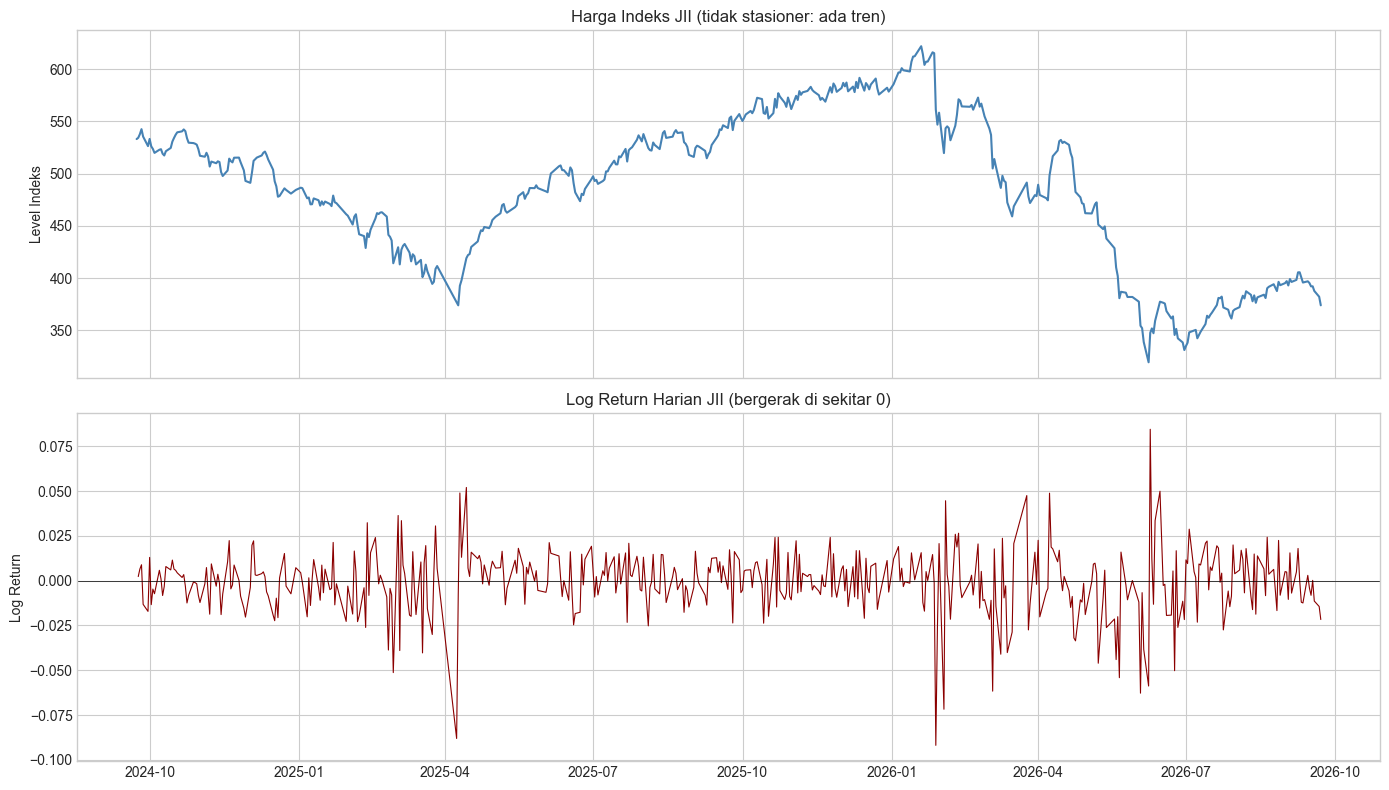

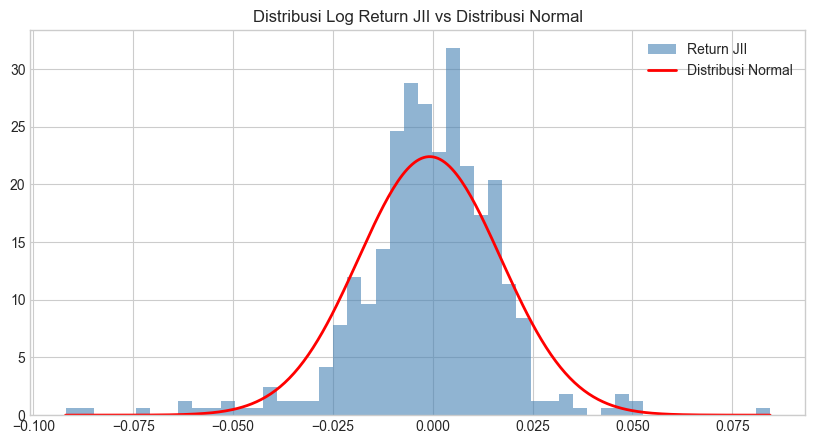

=== Distribusi Return JII ===
Skewness         : -0.6750
Excess Kurtosis  : 4.5842
Jarque-Bera p    : 0.0000 → TIDAK normal

=== Uji ADF (Stasioneritas) ===
Harga JII  : ADF = -0.8325, p = 0.8094 → TIDAK stasioner
Return JII : ADF = -11.0755, p = 0.0000 → Stasioner


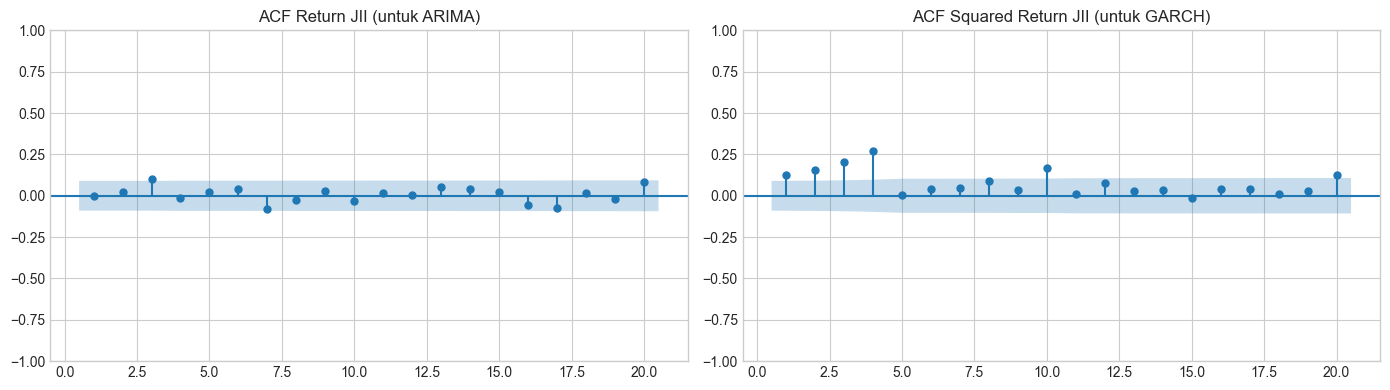

=== Uji Pola Autokorelasi JII ===
Ljung-Box return (lag 10)         : p = 0.4001
Ljung-Box squared return (lag 10) : p = 0.0000
ARCH-LM (lag 5)                   : p = 0.0000 → Ada ARCH effect


In [3]:
from scipy import stats

# ============================================================
# 3.1 Harga vs Return JII
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(jii_price, color='steelblue')
axes[0].set_title('Harga Indeks JII (tidak stasioner: ada tren)', fontsize=12)
axes[0].set_ylabel('Level Indeks')

axes[1].plot(jii_ret, color='darkred', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_title('Log Return Harian JII (bergerak di sekitar 0)', fontsize=12)
axes[1].set_ylabel('Log Return')

plt.tight_layout()
plt.show()

# ============================================================
# 3.2 Distribusi Return JII vs Normal
# ============================================================
skew_jii = jii_ret.skew()
kurt_jii = jii_ret.kurt()          # excess kurtosis (normal = 0)
jb_stat, jb_p = stats.jarque_bera(jii_ret)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(jii_ret, bins=50, density=True, alpha=0.6, color='steelblue', label='Return JII')
x = np.linspace(jii_ret.min(), jii_ret.max(), 300)
ax.plot(x, stats.norm.pdf(x, jii_ret.mean(), jii_ret.std()),
        color='red', linewidth=2, label='Distribusi Normal')
ax.set_title('Distribusi Log Return JII vs Distribusi Normal', fontsize=12)
ax.legend()
plt.show()

print("=== Distribusi Return JII ===")
print(f"Skewness         : {skew_jii:.4f}")
print(f"Excess Kurtosis  : {kurt_jii:.4f}")
print(f"Jarque-Bera p    : {jb_p:.4f} → "
      f"{'TIDAK normal' if jb_p < 0.05 else 'Normal'}")

# ============================================================
# 3.3 Uji ADF: Harga vs Return
# ============================================================
adf_price = adfuller(jii_price, autolag='AIC')
adf_ret   = adfuller(jii_ret, autolag='AIC')

print("\n=== Uji ADF (Stasioneritas) ===")
print(f"Harga JII  : ADF = {adf_price[0]:.4f}, p = {adf_price[1]:.4f} → "
      f"{'Stasioner' if adf_price[1] < 0.05 else 'TIDAK stasioner'}")
print(f"Return JII : ADF = {adf_ret[0]:.4f}, p = {adf_ret[1]:.4f} → "
      f"{'Stasioner' if adf_ret[1] < 0.05 else 'TIDAK stasioner'}")

# ============================================================
# 3.4 ACF Return vs ACF Squared Return
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(jii_ret, lags=20, ax=axes[0], zero=False)
axes[0].set_title('ACF Return JII (untuk ARIMA)')
plot_acf(jii_ret**2, lags=20, ax=axes[1], zero=False)
axes[1].set_title('ACF Squared Return JII (untuk GARCH)')
plt.tight_layout()
plt.show()

# ============================================================
# 3.5 Ljung-Box & ARCH-LM
# ============================================================
lb_ret = acorr_ljungbox(jii_ret, lags=[10], return_df=True)
lb_sq  = acorr_ljungbox(jii_ret**2, lags=[10], return_df=True)
arch_lm = het_arch(jii_ret - jii_ret.mean(), nlags=5)

print("=== Uji Pola Autokorelasi JII ===")
print(f"Ljung-Box return (lag 10)         : p = {lb_ret['lb_pvalue'].iloc[0]:.4f}")
print(f"Ljung-Box squared return (lag 10) : p = {lb_sq['lb_pvalue'].iloc[0]:.4f}")
print(f"ARCH-LM (lag 5)                   : p = {arch_lm[1]:.4f} → "
      f"{'Ada ARCH effect' if arch_lm[1] < 0.05 else 'Tidak ada ARCH effect'}")

In [4]:
# ============================================================
# 3.6 Ringkasan untuk Seluruh Saham + JII
# ============================================================
rows = []
for col in log_returns.columns:
    r = log_returns[col]
    rows.append({
        'Ticker'          : col,
        'Skewness'        : r.skew(),
        'Excess Kurtosis' : r.kurt(),
        'JB p-value'      : stats.jarque_bera(r)[1],
        'ADF p-value'     : adfuller(r, autolag='AIC')[1],
        'LB Return p'     : acorr_ljungbox(r, lags=[10], return_df=True)['lb_pvalue'].iloc[0],
        'ARCH-LM p'       : het_arch(r - r.mean(), nlags=5)[1],
    })

stylized_df = pd.DataFrame(rows).set_index('Ticker').round(4)

n = len(stylized_df)
print(f"Tidak berdistribusi normal (JB p < 0.05)   : {(stylized_df['JB p-value'] < 0.05).sum()}/{n}")
print(f"Return stasioner (ADF p < 0.05)            : {(stylized_df['ADF p-value'] < 0.05).sum()}/{n}")
print(f"Ada autokorelasi return (LB p < 0.05)      : {(stylized_df['LB Return p'] < 0.05).sum()}/{n}")
print(f"Ada ARCH effect (ARCH-LM p < 0.05)         : {(stylized_df['ARCH-LM p'] < 0.05).sum()}/{n}")

stylized_df.sort_values('Excess Kurtosis', ascending=False)

Tidak berdistribusi normal (JB p < 0.05)   : 29/29
Return stasioner (ADF p < 0.05)            : 29/29
Ada autokorelasi return (LB p < 0.05)      : 9/29
Ada ARCH effect (ARCH-LM p < 0.05)         : 21/29


,Skewness,Excess Kurtosis,JB p-value,ADF p-value,LB Return p,ARCH-LM p
Ticker,,,,,,
ADRO,-0.6470,20.4934,0.0,0.0,0.0001,0.0000
UNTR,-1.3045,10.2388,0.0,0.0,0.0092,0.5612
EXCL,-0.3432,7.1561,0.0,0.0,0.0533,0.0000
TLKM,-0.2869,5.6323,0.0,0.0,0.0681,0.0000
PGAS,-0.7577,5.5541,0.0,0.0,0.0082,0.0298
ENRG,0.2179,5.2864,0.0,0.0,0.0512,0.0006
BRIS,0.5221,5.2065,0.0,0.0,0.3659,0.0000
INKP,0.0880,5.0729,0.0,0.0,0.7057,0.0002
ADMR,0.8753,4.7110,0.0,0.0,0.2608,0.1420


## 4. ARIMA: Apakah Return Bisa Diprediksi?

Section 3 menunjukkan return JII tidak punya autokorelasi (Ljung-Box p = 0.40). Section ini membuktikannya secara praktis: kita coba tebak return harian dengan ARIMA, lalu bandingkan dengan tebakan paling sederhana.

**Apa itu ARIMA(p, d, q)?**
- **AR (p)**: menebak return hari ini dari return p hari sebelumnya
- **I (d)**: berapa kali data di-differencing supaya stasioner. Return sudah stasioner, jadi d = 0
- **MA (q)**: menebak return hari ini dari kesalahan tebakan q hari sebelumnya

**Langkah:**
1. **Pilih order terbaik** dari kombinasi p dan q (0–3) di data train (250 hari pertama, sama dengan Project 4), berdasarkan AIC terkecil. AIC mengukur keseimbangan antara seberapa pas model dan seberapa rumit modelnya; makin kecil makin baik.
2. **Walk-forward one-step-ahead**: setiap hari di periode test, model dilatih ulang hanya dengan data sampai kemarin, lalu menebak return hari ini. Tidak ada data masa depan yang "bocor" ke model.
3. **Bandingkan dengan 2 baseline:**
   - **Zero forecast**: selalu menebak return = 0 (harga besok sama dengan hari ini)
   - **Historical mean**: selalu menebak rata-rata return historis

**Metrik evaluasi:**
- **RMSE**: rata-rata besar kesalahan, menghukum kesalahan besar lebih berat. Makin kecil makin baik
- **MAE**: rata-rata besar kesalahan secara langsung. Makin kecil makin baik
- **Directional Accuracy**: persentase tebakan arah (naik/turun) yang benar. 50% sama dengan lempar koin

Kalau ARIMA tidak jauh lebih baik dari baseline, berarti return memang tidak bisa diprediksi dari pola masa lalunya.

In [5]:
import itertools

TRAIN_SIZE = 250
train_ret = jii_ret.iloc[:TRAIN_SIZE]
test_ret  = jii_ret.iloc[TRAIN_SIZE:]

print(f"Train : {train_ret.index.min().date()} s/d {train_ret.index.max().date()} ({len(train_ret)} hari)")
print(f"Test  : {test_ret.index.min().date()} s/d {test_ret.index.max().date()} ({len(test_ret)} hari)")

# ============================================================
# 4.1 Pemilihan order ARIMA berdasarkan AIC (data train)
# ============================================================
aic_results = []
for p, q in itertools.product(range(4), range(4)):
    try:
        fit = ARIMA(train_ret.values, order=(p, 0, q)).fit()
        aic_results.append({'Order': (p, 0, q), 'AIC': fit.aic})
    except Exception:
        continue

aic_df = pd.DataFrame(aic_results).sort_values('AIC').reset_index(drop=True)
best_order = aic_df.loc[0, 'Order']

print("\n=== 5 Order ARIMA Terbaik (AIC terkecil) ===")
print(aic_df.head().round(2).to_string(index=False))
print(f"\nOrder terpilih: ARIMA{best_order}")

best_fit = ARIMA(train_ret.values, order=best_order).fit()
print("\n=== Koefisien Model Terpilih ===")
print(best_fit.summary().tables[1])

Train : 2024-09-24 s/d 2025-10-14 (250 hari)
Test  : 2025-10-15 s/d 2026-09-22 (223 hari)

=== 5 Order ARIMA Terbaik (AIC terkecil) ===
    Order      AIC
(0, 0, 0) -1391.18
(0, 0, 1) -1389.22
(1, 0, 0) -1389.22
(2, 0, 0) -1387.89
(0, 0, 2) -1387.89

Order terpilih: ARIMA(0, 0, 0)

=== Koefisien Model Terpilih ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.001      0.179      0.858      -0.002       0.002
sigma2         0.0002   1.08e-05     20.442      0.000       0.000       0.000


=== Evaluasi Forecast Return (Periode Test) ===
                     RMSE       MAE  Directional Acc (%)  RMSE vs Zero (%)
Model                                                                     
ARIMA(0, 0, 0)   0.020629  0.014839            49.327354          0.001175
Historical Mean  0.020629  0.014839            49.327354          0.002992
Zero Forecast    0.020629  0.014820                  NaN          0.000000

Persentase hari naik di periode test: 46.2%
(Acuan: menebak 'selalu naik' akan benar sebanyak persentase ini)


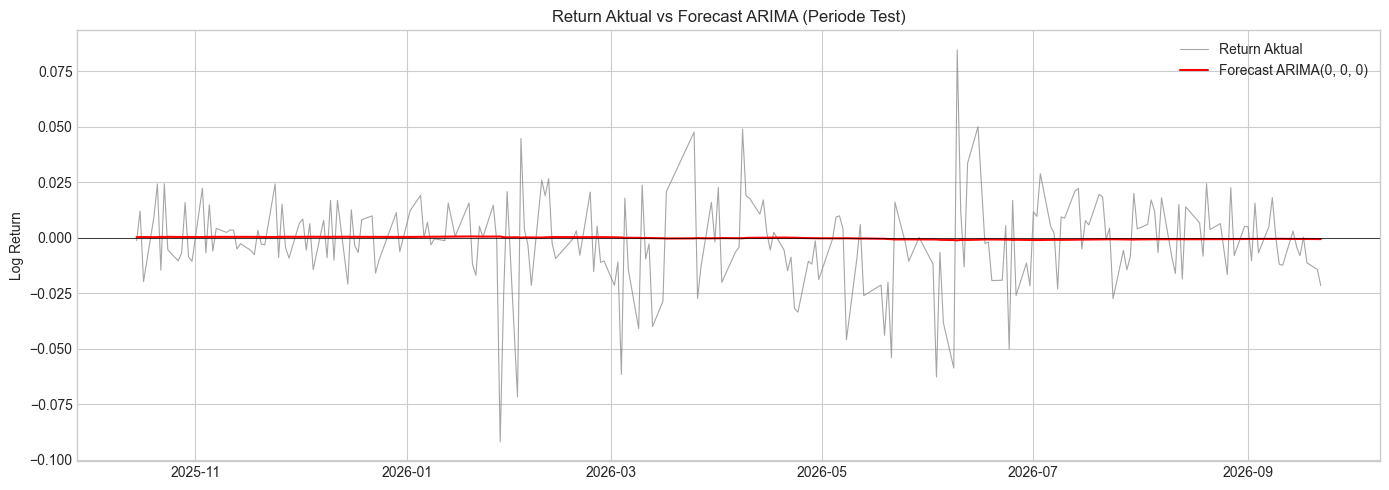

In [6]:
# ============================================================
# 4.2 Walk-forward one-step-ahead forecast
# (butuh ±1-2 menit karena model dilatih ulang tiap hari)
# ============================================================
arima_pred = []
mean_pred  = []

with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # sembunyikan ConvergenceWarning dari refit harian
    for t in range(len(test_ret)):
        history = jii_ret.iloc[:TRAIN_SIZE + t].values
        fit = ARIMA(history, order=best_order).fit()
        arima_pred.append(fit.forecast(1)[0])
        mean_pred.append(history.mean())

arima_pred = np.array(arima_pred)
mean_pred  = np.array(mean_pred)
zero_pred  = np.zeros(len(test_ret))
actual     = test_ret.values

# ============================================================
# 4.3 Evaluasi vs baseline
# ============================================================
def evaluate(actual, pred, has_direction=True):
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae  = mean_absolute_error(actual, pred)
    hit  = np.mean(np.sign(pred) == np.sign(actual)) * 100 if has_direction else np.nan
    return rmse, mae, hit

eval_rows = []
for name, pred, has_dir in [
    (f'ARIMA{best_order}', arima_pred, True),
    ('Historical Mean',    mean_pred,  True),
    ('Zero Forecast',      zero_pred,  False),
]:
    rmse, mae, hit = evaluate(actual, pred, has_dir)
    eval_rows.append({'Model': name, 'RMSE': rmse, 'MAE': mae, 'Directional Acc (%)': hit})

eval_df = pd.DataFrame(eval_rows).set_index('Model')
zero_rmse = eval_df.loc['Zero Forecast', 'RMSE']
eval_df['RMSE vs Zero (%)'] = (eval_df['RMSE'] / zero_rmse - 1) * 100

print("=== Evaluasi Forecast Return (Periode Test) ===")
print(eval_df.round(6))

up_days = np.mean(actual > 0) * 100
print(f"\nPersentase hari naik di periode test: {up_days:.1f}%")
print("(Acuan: menebak 'selalu naik' akan benar sebanyak persentase ini)")

# ============================================================
# 4.4 Visualisasi: Actual vs ARIMA Forecast
# ============================================================
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_ret.index, actual, color='gray', linewidth=0.8, alpha=0.7, label='Return Aktual')
ax.plot(test_ret.index, arima_pred, color='red', linewidth=1.5, label=f'Forecast ARIMA{best_order}')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Return Aktual vs Forecast ARIMA (Periode Test)', fontsize=12)
ax.set_ylabel('Log Return')
ax.legend()
plt.tight_layout()
plt.show()

## 5. GARCH: Model & Forecast Volatilitas

Section 3 menemukan ARCH effect pada return JII (ARCH-LM p = 0.0000): besar gerakan hari ini dipengaruhi besar gerakan hari-hari sebelumnya. GARCH adalah model yang dirancang khusus untuk pola ini.

**Cara kerja GARCH(1,1) dalam bahasa sederhana:**

Volatilitas hari ini = **ω** (volatilitas dasar) + **α** × (kejutan kemarin) + **β** × (volatilitas kemarin)

- **α (alpha)**: seberapa kuat pasar **bereaksi** terhadap kejutan kemarin. α besar berarti pasar cepat panik
- **β (beta)**: seberapa kuat pasar **mengingat** volatilitas kemarin. β besar berarti keributan bertahan lama
- **Persistence (α + β)**: seberapa lama volatilitas tinggi bertahan. Mendekati 1 berarti sangat lama
- **Half-life**: berapa hari sampai efek sebuah kejutan tinggal setengahnya

**3 model yang dibandingkan:**

| Model | Keterangan |
|---|---|
| GARCH(1,1)-Normal | Versi dasar, asumsi return berdistribusi normal |
| GARCH(1,1)-t | Memakai distribusi Student-t yang ekornya lebih tebal, karena Section 3 menunjukkan fat tails |
| GJR-GARCH(1,1)-t | Menambah **γ (gamma)**: reaksi tambahan jika kemarin return-nya **negatif**, karena Section 3 menunjukkan skewness negatif |

Parameter **ν (nu)** pada distribusi Student-t mengukur ketebalan ekor: makin kecil makin tebal. Di atas ±30 sudah hampir sama dengan normal.

**Langkah:**
1. Fit ketiga model di data train (250 hari), pilih yang terbaik berdasarkan AIC
2. Visualisasi volatilitas hasil model vs besar gerakan aktual
3. Walk-forward one-step-ahead forecast volatilitas di periode test (sama seperti Section 4)
4. Ringkasan persistence volatilitas untuk 28 saham

Return dikalikan 100 (dalam persen) supaya proses estimasi GARCH lebih stabil secara numerik.

In [11]:
# ============================================================
# 5.1 Fit 3 model GARCH di data train
# ============================================================
ret_pct   = jii_ret * 100
train_pct = ret_pct.iloc[:TRAIN_SIZE]
test_pct  = ret_pct.iloc[TRAIN_SIZE:]

garch_specs = {
    'GARCH(1,1)-Normal': dict(vol='GARCH', p=1, o=0, q=1, dist='normal'),
    'GARCH(1,1)-t'     : dict(vol='GARCH', p=1, o=0, q=1, dist='t'),
    'GJR-GARCH(1,1)-t' : dict(vol='GARCH', p=1, o=1, q=1, dist='t'),
}

def persistence_of(params):
    return params['alpha[1]'] + params['beta[1]'] + 0.5 * params.get('gamma[1]', 0)

def half_life(pers):
    if pers >= 0.999:
        return np.inf
    return np.log(0.5) / np.log(pers) if pers > 0 else 0

garch_fits = {}
compare_rows = []
for name, spec in garch_specs.items():
    res = arch_model(train_pct, mean='Constant', **spec).fit(disp='off', show_warning=False)
    garch_fits[name] = res
    pers = persistence_of(res.params)
    compare_rows.append({
        'Model'           : name,
        'Log-Likelihood'  : res.loglikelihood,
        'AIC'             : res.aic,
        'BIC'             : res.bic,
        'Persistence'     : pers,
        'Half-life (hari)': half_life(pers),
    })

compare_df = pd.DataFrame(compare_rows).set_index('Model').round(3)
best_garch = compare_df['AIC'].idxmin()

print("=== Perbandingan Model GARCH (Data Train) ===")
print(compare_df)
print(f"\nModel terbaik (AIC terkecil): {best_garch}")

# Parameter + p-value tiap model
print("\n=== Parameter Tiap Model ===")
for name, res in garch_fits.items():
    param_table = pd.DataFrame({'Koefisien': res.params, 'p-value': res.pvalues}).round(4)
    print(f"\n--- {name} ---")
    print(param_table)

=== Perbandingan Model GARCH (Data Train) ===
                   Log-Likelihood      AIC      BIC  Persistence  \
Model                                                              
GARCH(1,1)-Normal        -427.342  862.684  876.770        0.971   
GARCH(1,1)-t             -424.326  858.652  876.259        0.884   
GJR-GARCH(1,1)-t         -421.095  854.191  875.319        0.826   

                   Half-life (hari)  
Model                                
GARCH(1,1)-Normal            23.724  
GARCH(1,1)-t                  5.624  
GJR-GARCH(1,1)-t              3.633  

Model terbaik (AIC terkecil): GJR-GARCH(1,1)-t

=== Parameter Tiap Model ===

--- GARCH(1,1)-Normal ---
          Koefisien  p-value
mu          -0.0010   0.9899
omega        0.0755   0.3316
alpha[1]     0.1305   0.0038
beta[1]      0.8407   0.0000

--- GARCH(1,1)-t ---
          Koefisien  p-value
mu           0.0705   0.4893
omega        0.2391   0.2841
alpha[1]     0.1622   0.0813
beta[1]      0.7219   0.0002
nu    

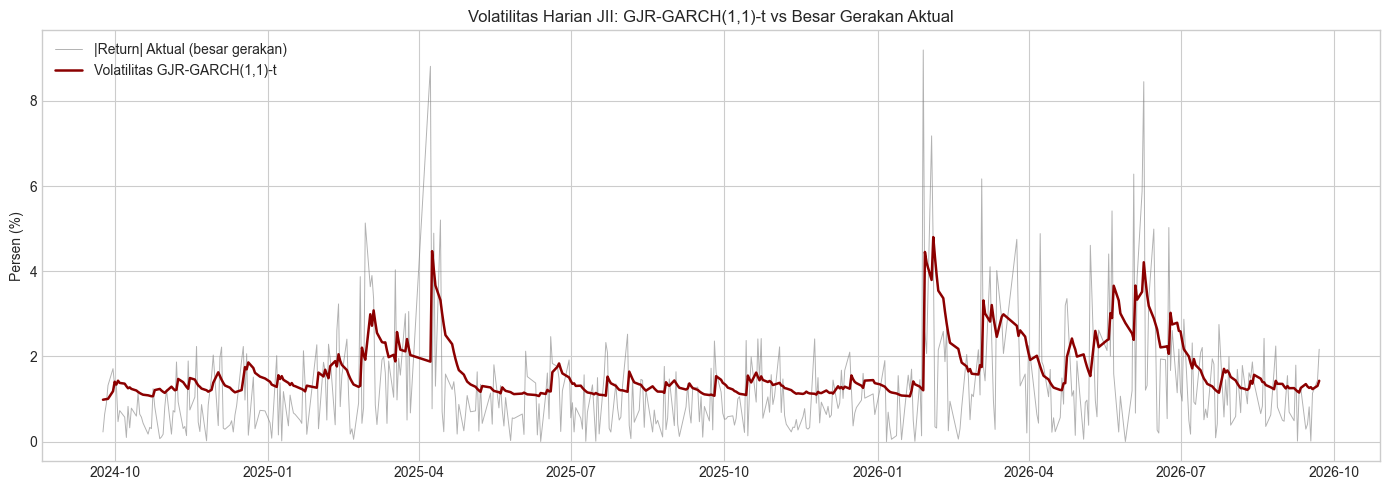

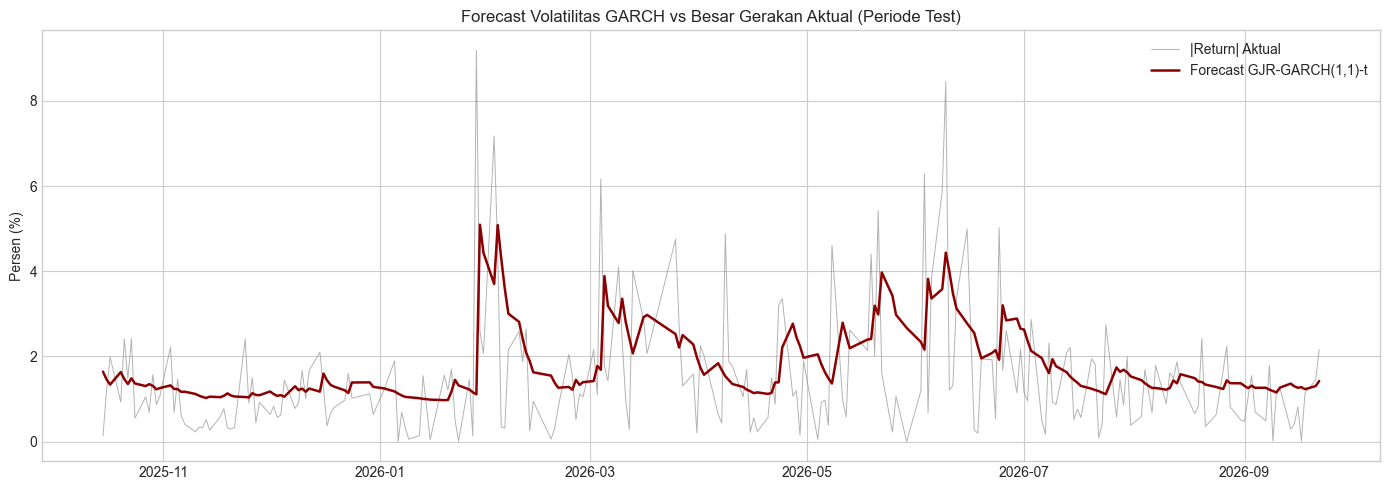

=== Korelasi Forecast Volatilitas vs |Return| Aktual (cek awal) ===
GARCH(1,1)-Normal   : 0.2810
GARCH(1,1)-t        : 0.2927
GJR-GARCH(1,1)-t    : 0.3661

(Evaluasi formal dilakukan di Section 7)


In [9]:
# ============================================================
# 5.2 Visualisasi: Volatilitas Model vs Besar Gerakan Aktual
# (fit di seluruh data, hanya untuk ilustrasi, bukan forecast)
# ============================================================
full_fit = arch_model(ret_pct, mean='Constant', **garch_specs[best_garch]).fit(disp='off', show_warning=False)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ret_pct.index, ret_pct.abs(), color='gray', linewidth=0.7, alpha=0.6,
        label='|Return| Aktual (besar gerakan)')
ax.plot(ret_pct.index, full_fit.conditional_volatility, color='darkred', linewidth=1.8,
        label=f'Volatilitas {best_garch}')
ax.set_title(f'Volatilitas Harian JII: {best_garch} vs Besar Gerakan Aktual', fontsize=12)
ax.set_ylabel('Persen (%)')
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 5.3 Walk-forward one-step-ahead forecast volatilitas
# (±1 menit, 3 model dilatih ulang tiap hari)
# ============================================================
garch_fc = {name: [] for name in garch_specs}

for t in range(len(test_pct)):
    history = ret_pct.iloc[:TRAIN_SIZE + t]
    for name, spec in garch_specs.items():
        res = arch_model(history, mean='Constant', **spec).fit(disp='off', show_warning=False)
        var_1d = res.forecast(horizon=1, reindex=False).variance.values[-1, 0]
        garch_fc[name].append(np.sqrt(var_1d))

garch_fc = pd.DataFrame(garch_fc, index=test_pct.index)   # volatilitas harian dalam %

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_pct.index, test_pct.abs(), color='gray', linewidth=0.7, alpha=0.6,
        label='|Return| Aktual')
ax.plot(garch_fc.index, garch_fc[best_garch], color='darkred', linewidth=1.8,
        label=f'Forecast {best_garch}')
ax.set_title('Forecast Volatilitas GARCH vs Besar Gerakan Aktual (Periode Test)', fontsize=12)
ax.set_ylabel('Persen (%)')
ax.legend()
plt.tight_layout()
plt.show()

print("=== Korelasi Forecast Volatilitas vs |Return| Aktual (cek awal) ===")
for name in garch_fc.columns:
    corr = np.corrcoef(garch_fc[name], test_pct.abs())[0, 1]
    print(f"{name:20s}: {corr:.4f}")
print("\n(Evaluasi formal dilakukan di Section 7)")

In [12]:
# ============================================================
# 5.4 Persistence volatilitas per saham (GARCH(1,1)-t, seluruh data)
# ============================================================
stock_rows = []
for col in stock_cols:
    r = stock_ret[col] * 100
    try:
        res = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off', show_warning=False)
        pers = persistence_of(res.params)
        stock_rows.append({
            'Ticker'          : col,
            'Alpha (reaksi)'  : res.params['alpha[1]'],
            'Beta (memori)'   : res.params['beta[1]'],
            'Persistence'     : pers,
            'Half-life (hari)': half_life(pers),
            'Nu (ekor)'       : res.params['nu'],
            'ARCH Effect'     : 'Ya' if stylized_df.loc[col, 'ARCH-LM p'] < 0.05 else 'Tidak',
        })
    except Exception as e:
        print(f"{col}: gagal fit ({e})")

jii_full = arch_model(ret_pct, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off', show_warning=False)
jii_pers = persistence_of(jii_full.params)
print(f"JII (acuan) → Persistence: {jii_pers:.3f}, Half-life: {half_life(jii_pers):.1f} hari\n")

stock_garch_df = pd.DataFrame(stock_rows).set_index('Ticker')
stock_garch_df.sort_values('Persistence', ascending=False).style.format({
    'Alpha (reaksi)'  : '{:.3f}',
    'Beta (memori)'   : '{:.3f}',
    'Persistence'     : '{:.3f}',
    'Half-life (hari)': '{:.1f}',
    'Nu (ekor)'       : '{:.2f}',
})

JII (acuan) → Persistence: 0.951, Half-life: 13.8 hari



,Alpha (reaksi),Beta (memori),Persistence,Half-life (hari),Nu (ekor),ARCH Effect
Ticker,,,,,,
WIFI,0.407,0.593,1.000,inf,3.22,Ya
EXCL,0.094,0.906,1.000,inf,4.76,Ya
TPIA,0.255,0.745,1.000,inf,3.61,Ya
BUMI,0.071,0.928,0.999,514.6,3.49,Ya
ARCI,0.057,0.940,0.997,245.1,4.37,Tidak
MBMA,0.031,0.960,0.990,70.1,3.46,Tidak
BKSL,0.116,0.874,0.990,66.4,4.34,Ya
RAJA,0.108,0.874,0.983,39.9,3.32,Tidak
KLBF,0.043,0.932,0.974,26.5,7.38,Tidak


## 6. Machine Learning untuk Volatilitas (Walk-Forward)

Section 5 menunjukkan GJR-GARCH-t bisa menangkap pola volatilitas JII. Pertanyaan section ini: **apakah model Machine Learning bisa lebih baik?**

**Model: Random Forest**

Random Forest terdiri dari ratusan decision tree. Setiap tree belajar aturan sederhana seperti "kalau volatilitas 5 hari terakhir > 2% dan kemarin turun, maka besok kemungkinan ribut". Hasil akhirnya adalah rata-rata tebakan semua tree, sehingga lebih stabil daripada satu tree saja.

Bedanya dengan GARCH: GARCH memakai **rumus tetap** (ω + α × kejutan + β × volatilitas kemarin), sedangkan Random Forest **mencari polanya sendiri** dari fitur yang diberikan, termasuk pola yang tidak linear.

**Target yang ditebak:** squared return hari ini (return²), yaitu ukuran "seberapa ribut" hari itu. Ini setara dengan varians yang ditebak GARCH, sehingga keduanya bisa dibandingkan secara adil di Section 7.

**Fitur (semua hanya memakai data sampai kemarin):**

| Fitur | Arti |
|---|---|
| `abs_ret_lag1` – `lag5` | Besar gerakan JII 1–5 hari terakhir |
| `ret_lag1` | Return kemarin (dengan arah naik/turun) |
| `neg_ret_lag1` | Return kemarin khusus jika negatif, untuk menangkap leverage effect dari Section 5 |
| `rv_5d`, `rv_10d`, `rv_22d` | Volatilitas 1 minggu, 2 minggu, dan 1 bulan terakhir |
| `stock_abs_mean_lag1` | Rata-rata besar gerakan 28 saham JII kemarin |
| `stock_dispersion_lag1` | Seberapa berbeda gerakan antar saham kemarin |

Dua fitur terakhir adalah **kelebihan ML**: GARCH hanya melihat indeks, sedangkan Random Forest bisa ikut melihat kondisi 28 sahamnya.

**Mencegah overfitting:** Project 4 menunjukkan bahwa optimasi berlebihan membuat model bagus di train tapi gagal di test. Karena itu, Random Forest di sini **tidak di-tuning**. Kedalaman tree dibatasi (`max_depth=4`) dan setiap daun minimal berisi 10 data (`min_samples_leaf=10`), supaya model tidak menghafal data.

**Walk-forward:** sama seperti Section 4 dan 5. Setiap hari di periode test, model dilatih ulang dengan data sampai kemarin, lalu menebak volatilitas hari ini.

In [13]:
# ============================================================
# 6.1 Feature engineering
# ============================================================
abs_ret       = ret_pct.abs()
stock_ret_pct = stock_ret * 100

feat = pd.DataFrame(index=ret_pct.index)

for lag in range(1, 6):
    feat[f'abs_ret_lag{lag}'] = abs_ret.shift(lag)

feat['ret_lag1']     = ret_pct.shift(1)
feat['neg_ret_lag1'] = ret_pct.shift(1).clip(upper=0)

for w in [5, 10, 22]:
    feat[f'rv_{w}d'] = ret_pct.rolling(w).std().shift(1)

feat['stock_abs_mean_lag1']   = stock_ret_pct.abs().mean(axis=1).shift(1)
feat['stock_dispersion_lag1'] = stock_ret_pct.std(axis=1).shift(1)

feat['target_var'] = ret_pct ** 2      # target: squared return (varians harian, %²)

ml_df = feat.dropna()
feature_cols = [c for c in ml_df.columns if c != 'target_var']

print(f"Jumlah fitur     : {len(feature_cols)}")
print(f"Data siap pakai  : {len(ml_df)} hari "
      f"({ml_df.index.min().date()} s/d {ml_df.index.max().date()})")
print(f"(22 hari pertama terbuang karena fitur rv_22d butuh 22 hari data)")

ml_df.head()

Jumlah fitur     : 12
Data siap pakai  : 451 hari (2024-10-24 s/d 2026-09-22)
(22 hari pertama terbuang karena fitur rv_22d butuh 22 hari data)


,abs_ret_lag1,abs_ret_lag2,abs_ret_lag3,abs_ret_lag4,abs_ret_lag5,ret_lag1,neg_ret_lag1,rv_5d,rv_10d,rv_22d,stock_abs_mean_lag1,stock_dispersion_lag1,target_var
Date,,,,,,,,,,,,,
2024-10-24,0.306574,0.336180,0.177774,0.436539,0.576902,-0.306574,-0.306574,0.340554,0.461939,0.836406,2.060818,3.788845,1.550438
2024-10-25,1.245166,0.306574,0.336180,0.177774,0.436539,-1.245166,-1.245166,0.690527,0.669095,0.880454,2.064922,2.915236,0.669174
2024-10-28,0.818030,1.245166,0.306574,0.336180,0.177774,-0.818030,-0.818030,0.665096,0.732880,0.884333,1.945078,2.098674,0.005152
2024-10-29,0.071780,0.818030,1.245166,0.306574,0.336180,-0.071780,-0.071780,0.621541,0.718179,0.858197,1.632648,2.589421,0.012025
2024-10-30,0.109661,0.071780,0.818030,1.245166,0.306574,-0.109661,-0.109661,0.507208,0.614825,0.814773,1.516631,2.403078,0.031004


Forecast selesai: 223 hari


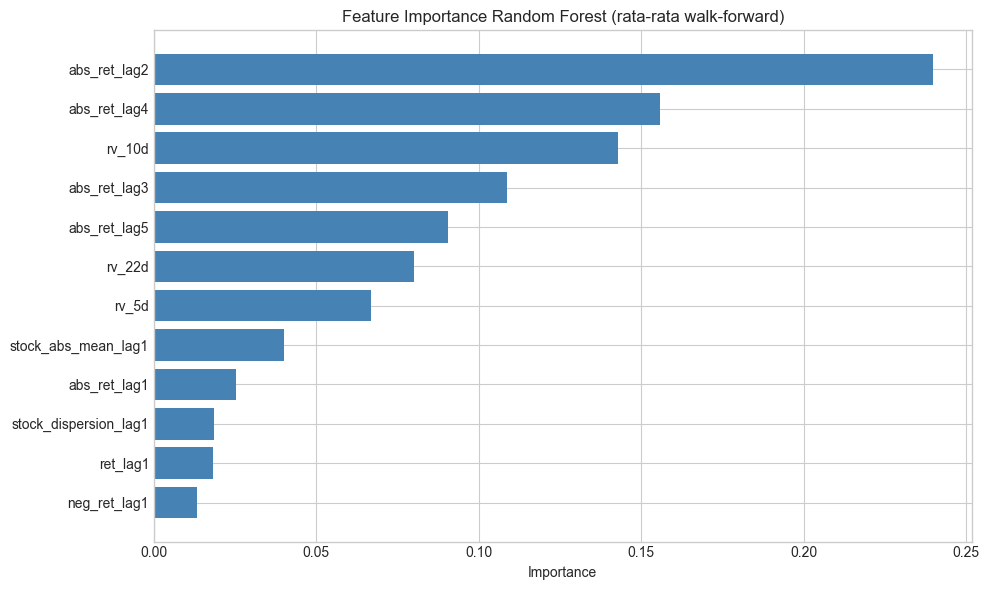

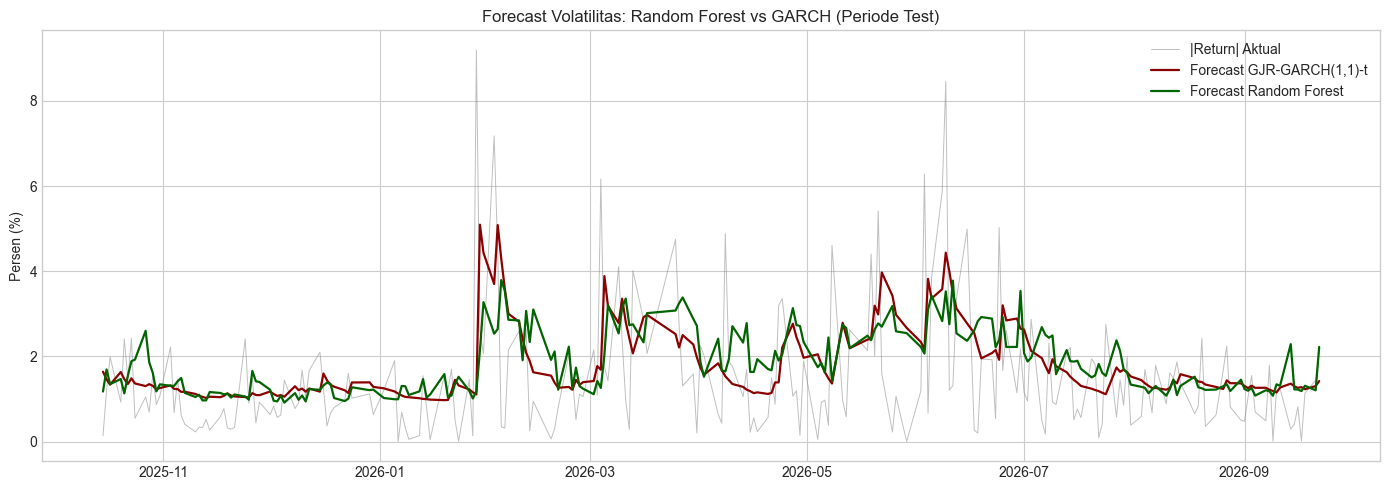

=== Korelasi Forecast Volatilitas vs |Return| Aktual (cek awal) ===
GARCH(1,1)-Normal   : 0.2810
GARCH(1,1)-t        : 0.2927
GJR-GARCH(1,1)-t    : 0.3661
Random Forest       : 0.2634

(Evaluasi formal dilakukan di Section 7)


In [14]:
# ============================================================
# 6.2 Walk-forward Random Forest
# (±1-2 menit, model dilatih ulang tiap hari)
# ============================================================
test_dates  = test_pct.index
rf_var_pred = []
importances = np.zeros(len(feature_cols))

for date in test_dates:
    train_part = ml_df[ml_df.index < date]
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(train_part[feature_cols], train_part['target_var'])
    rf_var_pred.append(rf.predict(ml_df.loc[[date], feature_cols])[0])
    importances += rf.feature_importances_

rf_fc = pd.Series(np.sqrt(rf_var_pred), index=test_dates, name='Random Forest')   # volatilitas harian, %
importances /= len(test_dates)

# Gabungkan semua forecast untuk dipakai di Section 7 & 8
vol_forecasts = garch_fc.copy()
vol_forecasts['Random Forest'] = rf_fc

print(f"Forecast selesai: {len(rf_fc)} hari")

# ============================================================
# 6.3 Feature importance (rata-rata dari semua model walk-forward)
# ============================================================
imp_df = pd.Series(importances, index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp_df.index, imp_df.values, color='steelblue')
ax.set_title('Feature Importance Random Forest (rata-rata walk-forward)', fontsize=12)
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

# ============================================================
# 6.4 Visualisasi: Random Forest vs GJR-GARCH vs Aktual
# ============================================================
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_dates, test_pct.abs(), color='gray', linewidth=0.7, alpha=0.5, label='|Return| Aktual')
ax.plot(test_dates, vol_forecasts[best_garch], color='darkred', linewidth=1.6, label=f'Forecast {best_garch}')
ax.plot(test_dates, vol_forecasts['Random Forest'], color='darkgreen', linewidth=1.6, label='Forecast Random Forest')
ax.set_title('Forecast Volatilitas: Random Forest vs GARCH (Periode Test)', fontsize=12)
ax.set_ylabel('Persen (%)')
ax.legend()
plt.tight_layout()
plt.show()

print("=== Korelasi Forecast Volatilitas vs |Return| Aktual (cek awal) ===")
for name in vol_forecasts.columns:
    corr = np.corrcoef(vol_forecasts[name], test_pct.abs())[0, 1]
    print(f"{name:20s}: {corr:.4f}")
print("\n(Evaluasi formal dilakukan di Section 7)")

## 7. Evaluasi Forecast: GARCH vs ML vs Baseline

Section 5 dan 6 hanya memakai korelasi sebagai cek awal. Section ini mengevaluasi semua model secara formal di periode test (223 hari).

**Model yang dibandingkan:**

| Kelompok | Model |
|---|---|
| GARCH | GARCH(1,1)-Normal, GARCH(1,1)-t, GJR-GARCH(1,1)-t |
| Machine Learning | Random Forest |
| Baseline (tanpa model) | **Historical Vol**: standar deviasi seluruh data sampai kemarin<br>**Rolling 22D**: standar deviasi 22 hari terakhir (±1 bulan bursa)<br>**EWMA (λ = 0.94)**: metode RiskMetrics dari J.P. Morgan, rata-rata tertimbang yang memberi bobot lebih besar ke hari-hari terbaru |

Baseline penting untuk menjawab: **apakah model yang rumit benar-benar lebih baik daripada cara sederhana?**

**Pembanding "kenyataan":** volatilitas harian sebenarnya tidak bisa dilihat langsung. Yang dipakai sebagai pengganti adalah **squared return (return²)** hari itu, lalu dibandingkan dengan **varians forecast (volatilitas²)** dari tiap model.

**Metrik (semua: makin kecil makin baik):**
- **RMSE**: rata-rata kesalahan, menghukum kesalahan besar lebih berat
- **MAE**: rata-rata kesalahan secara langsung
- **QLIKE**: metrik standar untuk evaluasi volatilitas. Menghukum lebih berat jika model **meremehkan** volatilitas. Ini sesuai kebutuhan manajemen risiko, karena meremehkan risiko lebih berbahaya daripada melebih-lebihkannya

**Uji Diebold-Mariano (DM):** menguji apakah perbedaan akurasi dua model **signifikan secara statistik** atau hanya kebetulan.
- DM negatif: model pertama (GJR-GARCH-t) lebih akurat
- p-value < 0.05: perbedaannya signifikan

In [15]:
# ============================================================
# 7.1 Baseline forecast (semua hanya memakai data sampai kemarin)
# ============================================================
# Historical Vol: std seluruh data sampai kemarin
hist_vol = [ret_pct.iloc[:TRAIN_SIZE + t].std() for t in range(len(test_pct))]

# Rolling 22 hari
roll_22 = ret_pct.rolling(22).std().shift(1).loc[test_dates]

# EWMA RiskMetrics (lambda = 0.94)
LAMBDA = 0.94
ewma_var = np.zeros(len(ret_pct))
ewma_var[0] = ret_pct.iloc[:22].var()
for i in range(1, len(ret_pct)):
    ewma_var[i] = LAMBDA * ewma_var[i - 1] + (1 - LAMBDA) * ret_pct.iloc[i - 1] ** 2
ewma_vol = pd.Series(np.sqrt(ewma_var), index=ret_pct.index).loc[test_dates]

all_fc = vol_forecasts.copy()
all_fc['Historical Vol'] = hist_vol
all_fc['Rolling 22D']    = roll_22.values
all_fc['EWMA (0.94)']    = ewma_vol.values

# ============================================================
# 7.2 Hitung metrik (dalam satuan varians, %²)
# ============================================================
proxy_var = (test_pct ** 2).values          # "kenyataan": squared return

def qlike_loss(actual_var, fc_var):
    return np.log(fc_var) + actual_var / fc_var

loss_mse   = {}
loss_qlike = {}
metric_rows = []

for name in all_fc.columns:
    fc_var = (all_fc[name] ** 2).values
    loss_mse[name]   = (proxy_var - fc_var) ** 2
    loss_qlike[name] = qlike_loss(proxy_var, fc_var)
    metric_rows.append({
        'Model': name,
        'RMSE' : np.sqrt(loss_mse[name].mean()),
        'MAE'  : np.abs(proxy_var - fc_var).mean(),
        'QLIKE': loss_qlike[name].mean(),
    })

metric_df = pd.DataFrame(metric_rows).set_index('Model')
base_qlike = metric_df.loc['Historical Vol', 'QLIKE']
metric_df['Rank QLIKE'] = metric_df['QLIKE'].rank().astype(int)
metric_df = metric_df.sort_values('QLIKE')

print("=== Evaluasi Forecast Volatilitas (Periode Test, 223 hari) ===")
print("(semua metrik: makin kecil makin baik)\n")
print(metric_df.round(4))

=== Evaluasi Forecast Volatilitas (Periode Test, 223 hari) ===
(semua metrik: makin kecil makin baik)

                      RMSE     MAE   QLIKE  Rank QLIKE
Model                                                 
GJR-GARCH(1,1)-t    9.5259  4.3578  2.3733           1
GARCH(1,1)-Normal   9.8024  4.5009  2.4327           2
GARCH(1,1)-t        9.7895  4.4132  2.4355           3
Random Forest       9.8011  4.5325  2.4448           4
EWMA (0.94)         9.8273  4.6398  2.4716           5
Rolling 22D        10.2056  4.9190  2.5624           6
Historical Vol     10.0599  4.1068  2.5842           7


=== Uji Diebold-Mariano: GJR-GARCH(1,1)-t vs Model Lain ===
(DM negatif = GJR-GARCH-t lebih akurat)

                     DM (QLIKE)  p (QLIKE) Signif QLIKE  DM (MSE)  p (MSE)  \
Dibandingkan dengan                                                          
GARCH(1,1)-Normal       -1.4788     0.1392        Tidak   -0.8438   0.3988   
GARCH(1,1)-t            -1.8387     0.0660        Tidak   -0.8497   0.3955   
Random Forest           -1.1660     0.2436        Tidak   -1.1806   0.2377   
Historical Vol          -1.2904     0.1969        Tidak   -0.9723   0.3309   
Rolling 22D             -2.0784     0.0377           Ya   -1.4960   0.1346   
EWMA (0.94)             -1.5217     0.1281        Tidak   -0.8939   0.3714   

                    Signif MSE  
Dibandingkan dengan             
GARCH(1,1)-Normal        Tidak  
GARCH(1,1)-t             Tidak  
Random Forest            Tidak  
Historical Vol           Tidak  
Rolling 22D              Tidak  
EWMA (0.94)              Tidak  


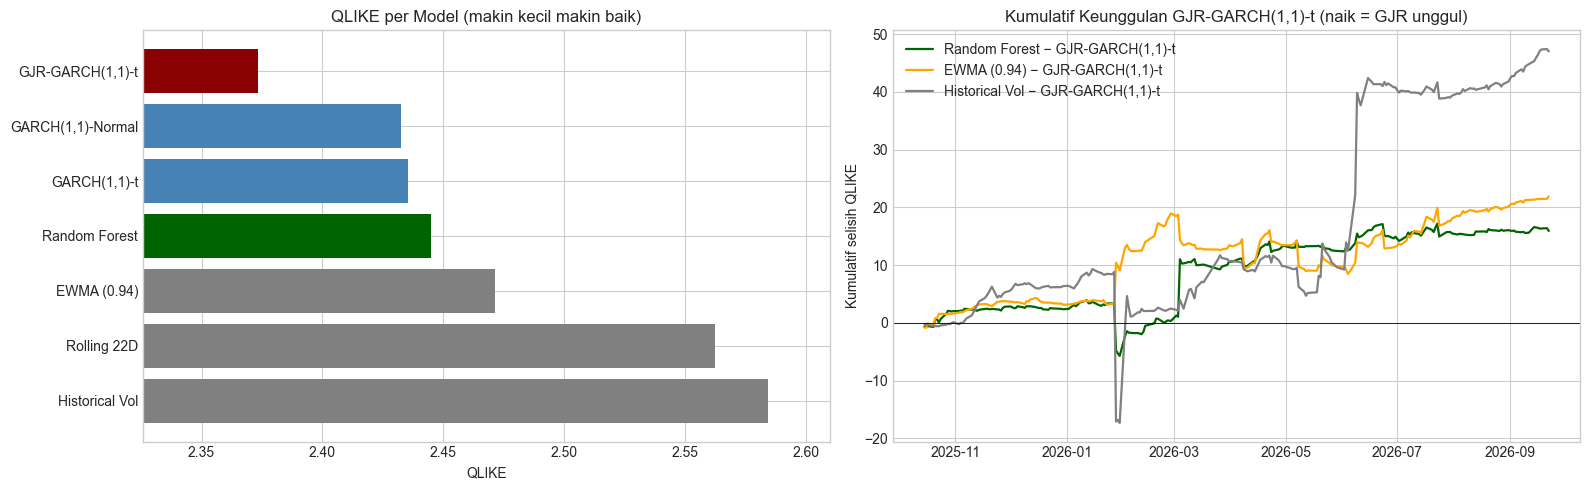

In [16]:
# ============================================================
# 7.3 Uji Diebold-Mariano: GJR-GARCH-t vs semua model lain
# ============================================================
def dm_test(loss_a, loss_b, lags=5):
    """DM < 0 → model A lebih akurat. Varians memakai Newey-West (HAC)."""
    d = loss_a - loss_b
    n = len(d)
    d_mean = d.mean()
    gamma = [np.sum((d[k:] - d_mean) * (d[:n - k] - d_mean)) / n for k in range(lags + 1)]
    var_d = gamma[0] + 2 * sum((1 - k / (lags + 1)) * gamma[k] for k in range(1, lags + 1))
    dm_stat = d_mean / np.sqrt(var_d / n)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return dm_stat, p_value

ref = best_garch
dm_rows = []
for name in all_fc.columns:
    if name == ref:
        continue
    dm_q, p_q = dm_test(loss_qlike[ref], loss_qlike[name])
    dm_m, p_m = dm_test(loss_mse[ref], loss_mse[name])
    dm_rows.append({
        'Dibandingkan dengan': name,
        'DM (QLIKE)'  : dm_q,
        'p (QLIKE)'   : p_q,
        'Signif QLIKE': 'Ya' if p_q < 0.05 else 'Tidak',
        'DM (MSE)'    : dm_m,
        'p (MSE)'     : p_m,
        'Signif MSE'  : 'Ya' if p_m < 0.05 else 'Tidak',
    })

dm_df = pd.DataFrame(dm_rows).set_index('Dibandingkan dengan').round(4)
print(f"=== Uji Diebold-Mariano: {ref} vs Model Lain ===")
print("(DM negatif = GJR-GARCH-t lebih akurat)\n")
print(dm_df)

# ============================================================
# 7.4 Visualisasi
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) QLIKE per model
colors = ['darkred' if n == ref else 'darkgreen' if n == 'Random Forest'
          else 'gray' if n in ['Historical Vol', 'Rolling 22D', 'EWMA (0.94)']
          else 'steelblue' for n in metric_df.index]
axes[0].barh(metric_df.index, metric_df['QLIKE'], color=colors)
axes[0].invert_yaxis()
axes[0].set_title('QLIKE per Model (makin kecil makin baik)', fontsize=12)
axes[0].set_xlabel('QLIKE')
axes[0].set_xlim(metric_df['QLIKE'].min() * 0.98, metric_df['QLIKE'].max() * 1.01)

# (b) Kumulatif selisih QLIKE: kapan GJR-GARCH-t unggul?
for name, color in [('Random Forest', 'darkgreen'),
                    ('EWMA (0.94)', 'orange'),
                    ('Historical Vol', 'gray')]:
    cum_diff = np.cumsum(loss_qlike[name] - loss_qlike[ref])
    axes[1].plot(test_dates, cum_diff, color=color, linewidth=1.6, label=f'{name} − {ref}')
axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].set_title(f'Kumulatif Keunggulan {ref} (naik = GJR unggul)', fontsize=12)
axes[1].set_ylabel('Kumulatif selisih QLIKE')
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Aplikasi: VaR Dinamis Berbasis GARCH

Section ini menyambungkan Project 5 dengan Project 3. Di Project 3, VaR dihitung dari data historis dengan asumsi volatilitas relatif stabil. Hasilnya, breach (kerugian melebihi VaR) **menumpuk di Februari–Maret 2026**, persis saat pasar sedang ribut.

Pertanyaannya: **kalau VaR ikut naik saat forecast volatilitas naik, apakah breach bisa lebih tersebar dan lebih akurat?**

**3 metode VaR yang dibandingkan (portofolio Rp 1 miliar di indeks JII):**

| Metode | Cara hitung | Sifat |
|---|---|---|
| **Historical 250D** | Persentil return 250 hari terakhir (metode Project 3) | Lambat bereaksi |
| **EWMA-Normal** | Volatilitas EWMA (λ = 0.94) × kuantil distribusi normal (standar RiskMetrics) | Dinamis, asumsi normal |
| **GJR-GARCH-t** | Forecast volatilitas GJR-GARCH × kuantil distribusi Student-t | Dinamis, ekor tebal, asimetris |

Semua VaR dihitung walk-forward: VaR hari ini hanya memakai data sampai kemarin.

**Uji backtesting:**
- **Kupiec (POF)**: apakah **jumlah** breach sesuai target? Di VaR 95%, breach seharusnya ±5% dari hari; di VaR 99%, ±1%. p > 0.05 berarti jumlahnya wajar
- **Christoffersen (Independence)**: apakah breach **tersebar acak** atau **bergerombol**? p > 0.05 berarti tidak bergerombol. Ini uji yang tidak ada di Project 3, dan justru inti masalah yang ingin diperbaiki
- **Conditional Coverage**: gabungan keduanya. p > 0.05 berarti jumlah breach wajar **dan** tidak bergerombol

**Ukuran tambahan:**
- **Rata-rata VaR**: seberapa besar cadangan risiko yang disiapkan. Makin besar, makin mahal (modal "menganggur")
- **Rata-rata kelebihan saat breach**: seberapa jauh kerugian melewati VaR ketika breach terjadi. Makin kecil makin baik

VaR yang ideal: jumlah breach mendekati target, tidak bergerombol, dan cadangannya tidak berlebihan.

In [17]:
# ============================================================
# 8.1 Hitung VaR walk-forward untuk 3 metode
# (±30 detik, GJR-GARCH-t dilatih ulang tiap hari)
# ============================================================
PORTFOLIO = 1_000_000_000      # Rp 1 miliar, sama seperti Project 3
LEVELS    = [0.95, 0.99]
WINDOW    = 250

var_results = {('Historical 250D', lvl): [] for lvl in LEVELS}
var_results.update({('EWMA-Normal', lvl): [] for lvl in LEVELS})
var_results.update({('GJR-GARCH-t', lvl): [] for lvl in LEVELS})

for t in range(len(test_pct)):
    end = TRAIN_SIZE + t
    history = ret_pct.iloc[:end]

    # GJR-GARCH-t
    res = arch_model(history, mean='Constant', **garch_specs[best_garch]).fit(disp='off', show_warning=False)
    fc = res.forecast(horizon=1, reindex=False)
    mu  = fc.mean.values[-1, 0]
    sig = np.sqrt(fc.variance.values[-1, 0])
    dist_params = res.params[res.model.distribution.parameter_names()].values

    for lvl in LEVELS:
        # Historical 250 hari terakhir
        var_results[('Historical 250D', lvl)].append(
            np.percentile(ret_pct.iloc[end - WINDOW:end], (1 - lvl) * 100))
        # EWMA dengan distribusi normal
        var_results[('EWMA-Normal', lvl)].append(
            stats.norm.ppf(1 - lvl) * ewma_vol.iloc[t])
        # GJR-GARCH dengan distribusi Student-t
        q = res.model.distribution.ppf(1 - lvl, dist_params)
        var_results[('GJR-GARCH-t', lvl)].append(mu + sig * q)

var_df = pd.DataFrame(var_results, index=test_dates)   # VaR dalam % (angka negatif)
print(f"VaR selesai dihitung untuk {len(var_df)} hari test")
var_df.head()

VaR selesai dihitung untuk 223 hari test


Historical 250D           EWMA-Normal           GJR-GARCH-t  \
                      0.95      0.99        0.95      0.99        0.95   
Date                                                                     
2025-10-15       -2.281984 -3.967831   -1.811241 -2.561673   -2.583870   
2025-10-16       -2.281984 -3.967831   -1.756945 -2.484881   -2.295724   
2025-10-17       -2.281984 -3.967831   -1.769616 -2.502801   -2.094301   
2025-10-20       -2.281984 -3.967831   -1.893520 -2.678041   -2.580379   
2025-10-21       -2.281984 -3.967831   -1.873622 -2.649899   -2.311611   

                      
                0.99  
Date                  
2025-10-15 -4.075133  
2025-10-16 -3.624367  
2025-10-17 -3.310975  
2025-10-20 -4.051340  
2025-10-21 -3.634880

In [18]:
# ============================================================
# 8.2 Backtesting: Kupiec, Christoffersen, Conditional Coverage
# ============================================================
def safe_log(x):
    return np.log(x) if x > 0 else 0.0

def kupiec_test(breaches, p):
    n, x = len(breaches), breaches.sum()
    pi_hat = x / n
    ll_null = (n - x) * safe_log(1 - p) + x * safe_log(p)
    ll_alt  = (n - x) * safe_log(1 - pi_hat) + x * safe_log(pi_hat)
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1)

def christoffersen_test(breaches):
    b = breaches.astype(int)
    n00 = n01 = n10 = n11 = 0
    for prev, curr in zip(b[:-1], b[1:]):
        if   prev == 0 and curr == 0: n00 += 1
        elif prev == 0 and curr == 1: n01 += 1
        elif prev == 1 and curr == 0: n10 += 1
        else:                         n11 += 1
    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_null = (n00 + n10) * safe_log(1 - pi) + (n01 + n11) * safe_log(pi)
    ll_alt  = (n00 * safe_log(1 - pi01) + n01 * safe_log(pi01)
               + n10 * safe_log(1 - pi11) + n11 * safe_log(pi11))
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1), n11

actual_ret = test_pct.values
bt_rows = []

for lvl in LEVELS:
    p = 1 - lvl
    for method in ['Historical 250D', 'EWMA-Normal', 'GJR-GARCH-t']:
        var_series = var_df[(method, lvl)].values
        breaches = actual_ret < var_series

        lr_pof, p_pof = kupiec_test(breaches, p)
        lr_ind, p_ind, consecutive = christoffersen_test(breaches)
        p_cc = 1 - stats.chi2.cdf(lr_pof + lr_ind, df=2)

        excess = (actual_ret[breaches] - var_series[breaches]).mean() if breaches.any() else 0

        bt_rows.append({
            'Level'             : f'{int(lvl*100)}%',
            'Metode'            : method,
            'Breach'            : int(breaches.sum()),
            'Breach Rate (%)'   : breaches.mean() * 100,
            'Target (%)'        : p * 100,
            'Breach Berturut'   : consecutive,
            'Kupiec p'          : p_pof,
            'Christoffersen p'  : p_ind,
            'Cond. Coverage p'  : p_cc,
            'Avg VaR (Rp jt)'   : var_series.mean() / 100 * PORTFOLIO / 1e6,
            'Avg Kelebihan (Rp jt)': excess / 100 * PORTFOLIO / 1e6,
        })

bt_df = pd.DataFrame(bt_rows).set_index(['Level', 'Metode']).round(3)
print("=== Backtesting VaR (Periode Test, 223 hari, portofolio Rp 1 miliar) ===")
print("p > 0.05 = lolos uji\n")
bt_df

=== Backtesting VaR (Periode Test, 223 hari, portofolio Rp 1 miliar) ===
p > 0.05 = lolos uji



Breach  Breach Rate (%)  Target (%)  Breach Berturut  \
Level Metode                                                                  
95%   Historical 250D      18            8.072         5.0                4   
      EWMA-Normal          14            6.278         5.0                0   
      GJR-GARCH-t          13            5.830         5.0                0   
99%   Historical 250D       4            1.794         1.0                0   
      EWMA-Normal           6            2.691         1.0                0   
      GJR-GARCH-t           5            2.242         1.0                0   

                       Kupiec p  Christoffersen p  Cond. Coverage p  \
Level Metode                                                          
95%   Historical 250D     0.052             0.050             0.022   
      EWMA-Normal         0.399             0.186             0.292   
      GJR-GARCH-t         0.579             0.203             0.382   
99%   Historical 250D     0.284             0.702             0.523   
      EWMA-Normal         0.036             0.564             0.094   
      GJR-GARCH-t         0.109             0.631             0.247   

                       Avg VaR (Rp jt)  Avg Kelebihan (Rp jt)  
Level Metode                                                   
95%   Historical 250D          -26.521                -21.493  
      EWMA-Normal              -31.752                -15.946  
      GJR-GARCH-t              -27.873                -18.622  
99%   Historical 250D          -54.695                -20.748  
      EWMA-Normal              -44.907                -18.326  
      GJR-GARCH-t              -44.622                -20.854

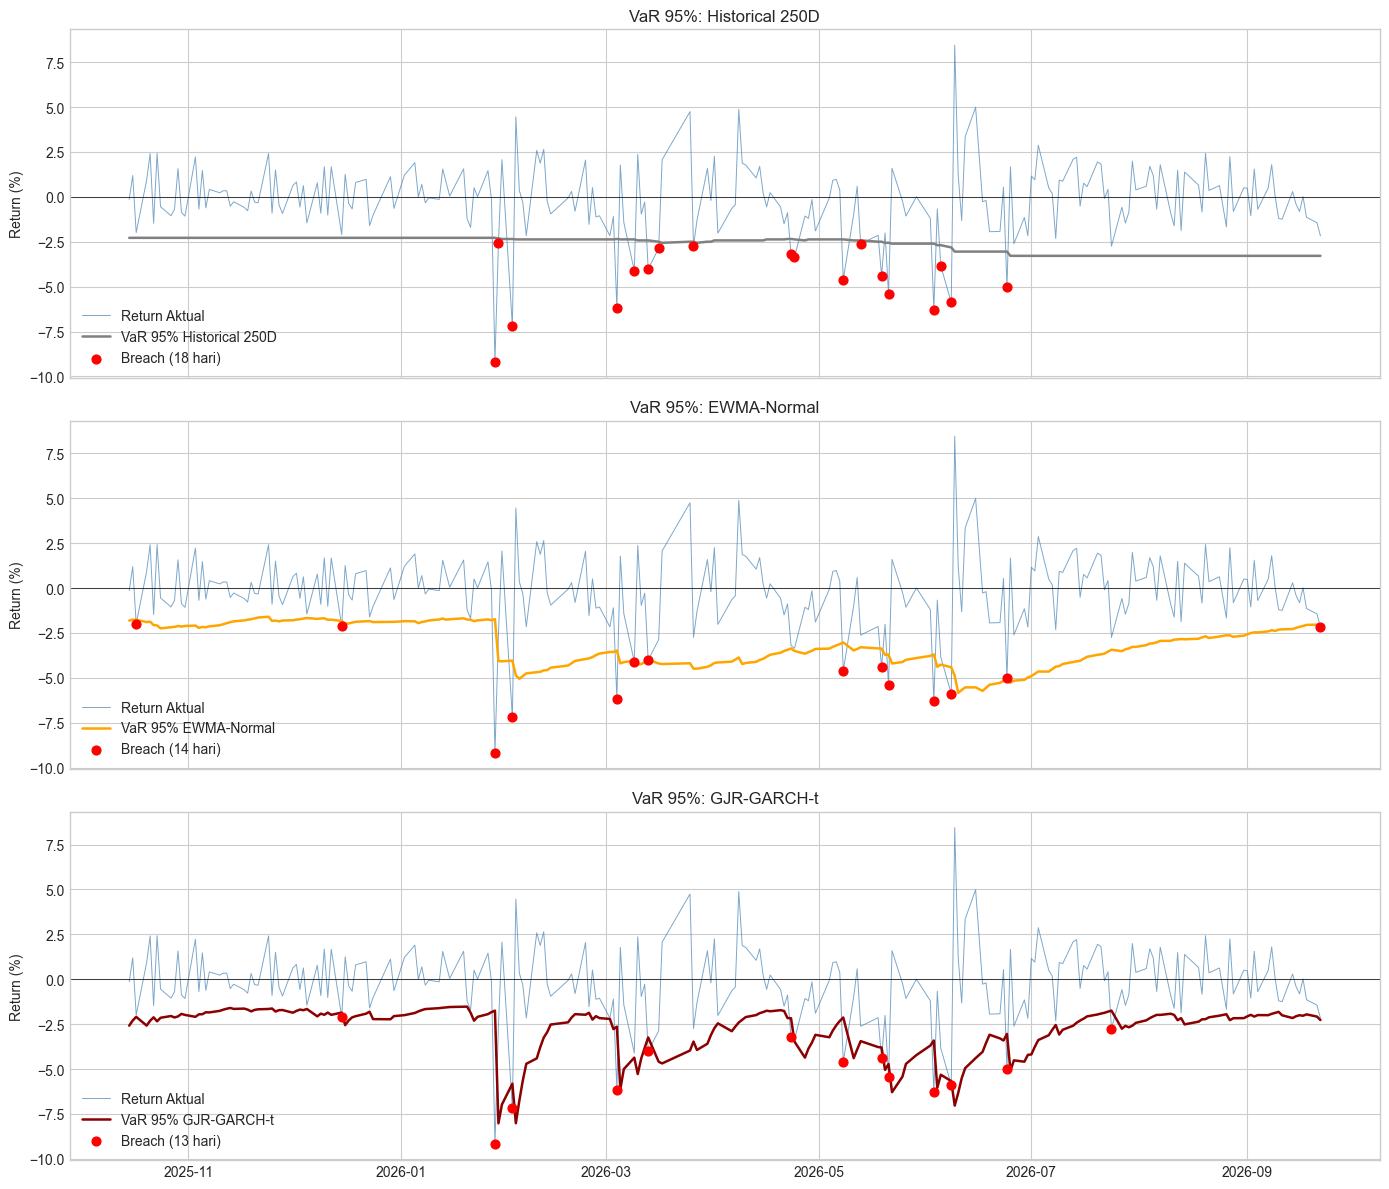

In [19]:
# ============================================================
# 8.3 Visualisasi: VaR 95% & lokasi breach
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, method, color in zip(axes,
                             ['Historical 250D', 'EWMA-Normal', 'GJR-GARCH-t'],
                             ['gray', 'orange', 'darkred']):
    var_95 = var_df[(method, 0.95)]
    breaches = test_pct < var_95

    ax.plot(test_dates, test_pct, color='steelblue', linewidth=0.7, alpha=0.7, label='Return Aktual')
    ax.plot(test_dates, var_95, color=color, linewidth=1.8, label=f'VaR 95% {method}')
    ax.scatter(test_dates[breaches], test_pct[breaches], color='red', s=40, zorder=5,
               label=f'Breach ({breaches.sum()} hari)')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_title(f'VaR 95%: {method}', fontsize=12)
    ax.set_ylabel('Return (%)')
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 9. Insight & Kesimpulan

### Pertanyaan Utama
**Apakah return dan volatilitas indeks JII bisa diprediksi, dan model mana yang paling baik?**

**Jawaban singkat:** arah pergerakan (return) **tidak bisa** diprediksi, tetapi tingkat keributan pasar (volatilitas) **bisa** diprediksi. Model terbaik adalah **GJR-GARCH(1,1) dengan distribusi Student-t**, dan manfaat praktisnya terlihat jelas saat dipakai untuk menghitung VaR.

---

### Ringkasan Temuan per Section

**1. Karakteristik data (Section 3)**
- Return seluruh 29 series (28 saham + JII) **tidak berdistribusi normal**. JII memiliki excess kurtosis 4.58 (ekor tebal) dan skewness −0.68 (penurunan tajam lebih ekstrem daripada kenaikan)
- Return **tidak memiliki autokorelasi** (Ljung-Box p = 0.40), tetapi squared return **memiliki autokorelasi kuat** (p = 0.0000). Terdapat **volatility clustering** pada JII dan 21 dari 29 series
- Return ekstrem saham individual banyak berhenti di sekitar +25% dan −15%, sesuai batas **ARA/ARB** Bursa Efek Indonesia

**2. Return tidak bisa diprediksi (Section 4)**
- Pemilihan order berdasarkan AIC menghasilkan **ARIMA(0,0,0)**, yaitu model tanpa komponen AR dan MA
- Secara walk-forward, ARIMA **tidak lebih akurat** daripada tebakan "return = 0" (RMSE identik: 0.0206), dengan akurasi arah hanya **49.3%**, lebih rendah dari lempar koin
- Temuan ini konsisten dengan **Efficient Market Hypothesis bentuk lemah**

**3. Volatilitas bisa diprediksi (Section 5)**
- **GJR-GARCH(1,1)-t** unggul dari GARCH-Normal dan GARCH-t berdasarkan log-likelihood, AIC, dan BIC
- Ditemukan **leverage effect**: kejutan positif tidak menambah volatilitas (α ≈ 0), sedangkan kejutan negatif menambah volatilitas (γ = 0.278, signifikan di level 10%)
- **Pemilihan distribusi memengaruhi kesimpulan**: dengan distribusi normal, half-life kejutan diperkirakan ±24 hari, sedangkan dengan Student-t hanya ±4 hari
- Perilaku volatilitas **sangat berbeda antar saham**: saham defensif (TLKM, ICBP, INDF, UNVR) cepat pulih, sedangkan beberapa saham volatil (WIFI, EXCL, TPIA) memiliki persistence ≈ 1, indikasi **structural break**

**4. Machine Learning tidak mengalahkan GARCH (Section 6)**
- Random Forest memiliki korelasi forecast terendah (0.263) dibanding seluruh model GARCH (0.281–0.366)
- Random Forest **tidak menangkap leverage effect** dan **tidak bisa memprediksi di luar rentang data train**, sehingga forecast-nya tertahan di sekitar 3.8% saat krisis
- Dengan data harian yang terbatas, struktur yang sudah tertanam dalam GARCH lebih berharga daripada fleksibilitas ML

**5. Evaluasi formal (Section 7)**
- Peringkat QLIKE menunjukkan pola yang konsisten: **GARCH > Machine Learning > baseline**
- GJR-GARCH-t menempati peringkat pertama (QLIKE 2.373) dan mengalahkan metode standar industri **EWMA RiskMetrics** (2.472)
- Uji Diebold-Mariano menunjukkan GJR-GARCH-t **lebih akurat dari seluruh model** (semua DM negatif), tetapi **signifikan secara statistik hanya terhadap Rolling 22D** (p = 0.038)
- Perbedaan akurasi antar model **ditentukan oleh segelintir hari krisis**; pada periode tenang semua model memberikan hasil yang hampir sama

**6. Aplikasi pada VaR (Section 8)**

| Metode | VaR 95% | VaR 99% | Breach Berturut (95%) |
|---|---|---|---|
| Historical 250D (metode Project 3) | ❌ Gagal Conditional Coverage (18 breach, 8.07%) | ✅ Lolos, tetapi paling mahal (Rp 54.7 jt) | 4 |
| EWMA-Normal | ✅ Lolos, tetapi paling mahal (Rp 31.8 jt) | ❌ Gagal Kupiec (2.69%) | 0 |
| **GJR-GARCH-t** | ✅ **Lolos semua uji (5.83%)** | ✅ **Lolos semua uji, paling hemat (Rp 44.6 jt)** | **0** |

- **GJR-GARCH-t adalah satu-satunya metode yang lolos seluruh uji** di kedua level kepercayaan
- VaR dinamis **menghilangkan breach berturut-turut**, masalah yang ditemukan di Project 3 (breach menumpuk pada Februari–Maret 2026)
- Distribusi normal kembali terbukti **meremehkan risiko ekstrem** (EWMA gagal di VaR 99%), konsisten dengan temuan Monte Carlo di Project 3

---

### Keterkaitan dengan Rangkaian Project

| Project | Fokus | Kontribusi Project 5 |
|---|---|---|
| 1. IDX30 Screener | Memilih kandidat saham | Menunjukkan bahwa momentum return sulit diprediksi dari harga masa lalu saja |
| 2. IDXBUMN20 Optimizer | Mengalokasikan bobot | Volatilitas yang berubah-ubah menunjukkan bobot optimal sebaiknya ditinjau ulang secara berkala |
| 3. LQ45 Risk Dashboard | Mengukur tail risk | **Memperbaiki** VaR statis dengan VaR dinamis berbasis GARCH |
| 4. LQ45 Backtesting Engine | Menguji strategi dengan walk-forward | Memakai **kerangka walk-forward yang sama** untuk seluruh evaluasi forecast |
| 5. JII Forecasting | Memprediksi return & volatilitas | Menutup rangkaian dari **deskriptif ke prediktif** |

---

### Keterbatasan
1. **Periode data pendek** (±2 tahun, periode test 223 hari). Uji Diebold-Mariano dan backtest VaR 99% memiliki kekuatan statistik terbatas
2. **Proxy volatilitas penuh noise**: squared return harian hanya pendekatan kasar dari volatilitas sebenarnya
3. **Survivorship bias**: konstituen JII yang dipakai adalah daftar periode Juni–November 2026 dan diterapkan ke seluruh periode data, sehingga saham yang sebelumnya keluar dari indeks tidak ikut dianalisis
4. **Structural break** tidak dimodelkan: GARCH standar mengasumsikan parameter konstan sepanjang waktu
5. **Kejutan pertama tidak bisa diantisipasi**: seluruh model hanya bereaksi setelah volatilitas mulai naik
6. **Random Forest tidak di-tuning** secara sengaja untuk menghindari overfitting, sehingga performanya mungkin bukan batas atas kemampuan ML

### Pengembangan Lanjutan
1. **Data intraday** untuk menghitung *realized volatility* yang jauh lebih akurat sebagai pembanding
2. **Model HAR-RV** (Heterogeneous Autoregressive) yang menjadi standar forecasting volatilitas berbasis realized volatility
3. **Regime-switching GARCH** untuk menangani structural break
4. **DCC-GARCH** (multivariat) untuk memodelkan volatilitas dan korelasi antar saham secara bersamaan, sehingga bisa langsung dipakai untuk VaR portofolio
5. **Backtesting Expected Shortfall (CVaR)**, bukan hanya VaR, untuk mengukur besarnya kerugian saat breach